# Task 3: Hyperparameter Tuning (Titanic)
The goal of this task is to understand how hyperparameters control model behaviour and how systematic search strategies find better configurations without using the test set.

**Parameters vs Hyperparameters**
- **Parameters** are learned automatically from data during training (e.g. split thresholds in a decision tree, weights in SVM's support vectors).
- **Hyperparameters** are set by the practitioner before training and govern how learning happens (e.g. `max_depth`, `learning_rate`, `C`). They cannot be learned from data and must be selected through search.
- Hyperparameters directly control the **bias-variance trade-off**: too permissive settings cause overfitting (high train, low CV score); too restrictive settings cause underfitting (low both).

### Step 1: Setup and Exploratory Data Analysis

In this step we:
- Configure global settings (`DRY_RUN`, `RANDOM_STATE = 42`) and load the dataset
- Check data dimensions and columns with missing values (`Age`, `Cabin`, `Embarked`)
- Visualize baseline survival distributions across gender and ticket class

Dataset Shape: 891 rows, 12 columns

Missing Value Summary:


C:\Users\rithy\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Missing Count
Age,177
Cabin,687
Embarked,2



Overall Survival Rate: 38.38%


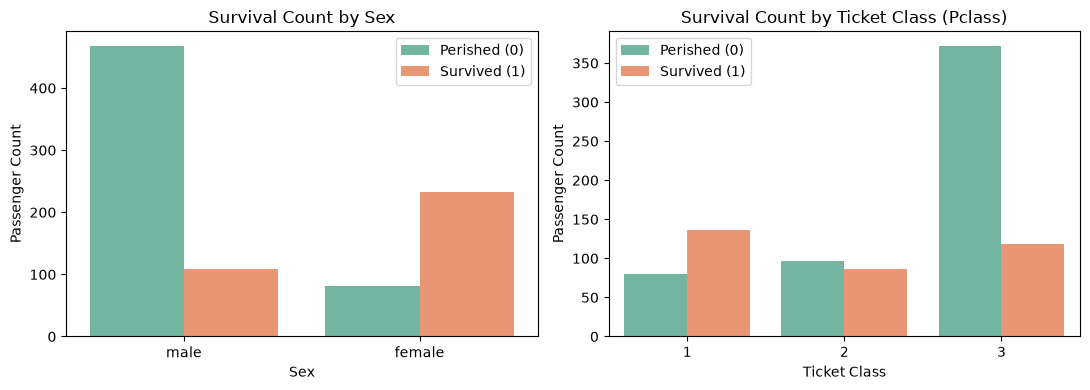

In [2]:
  
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from time import perf_counter
from scipy.stats import randint

from sklearn.model_selection import (
    train_test_split, RepeatedStratifiedKFold,
    GridSearchCV, RandomizedSearchCV, cross_validate
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)
from sklearn.base import clone
from xgboost import XGBClassifier
import optuna

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Global configuration
RANDOM_STATE = 42
N_JOBS = -1
DRY_RUN = True  # Set to False when ready for full search run

N_ITER = 5 if DRY_RUN else 50
N_TRIALS = 5 if DRY_RUN else 50
DATA_PATH = r"C:\Users\rithy\OneDrive\Desktop\marvel_level3\task3\Titanic-Dataset.csv"
results = []  # Global list to store metrics across all models and methods

# Load raw dataset
df_raw = pd.read_csv(DATA_PATH)
print(f"Dataset Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")

# Missing values summary
missing_summary = pd.DataFrame({"Missing Count": df_raw.isna().sum()})
print("\nMissing Value Summary:")
display(missing_summary[missing_summary["Missing Count"] > 0])

# Overall survival rate
print(f"\nOverall Survival Rate: {df_raw['Survived'].mean():.2%}")

# Demographic countplots
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df_raw, x="Sex", hue="Survived", palette="Set2", ax=axes[0])
axes[0].set_title("Survival Count by Sex")
axes[0].set_xlabel("Sex")
axes[0].set_ylabel("Passenger Count")
axes[0].legend(["Perished (0)", "Survived (1)"])

sns.countplot(data=df_raw, x="Pclass", hue="Survived", palette="Set2", ax=axes[1])
axes[1].set_title("Survival Count by Ticket Class (Pclass)")
axes[1].set_xlabel("Ticket Class")
axes[1].set_ylabel("Passenger Count")
axes[1].legend(["Perished (0)", "Survived (1)"])

plt.tight_layout()
plt.show()

### Step 2: Feature Engineering and Train-Test Split

Using the same logic established in Task 2, we perform row-wise transformations before splitting:
- Create `FamilySize` (`SibSp + Parch + 1`) and `IsAlone`
- Extract and standardize `Title` (`Miss`, `Mrs`, `Mr`, `Master`, `Rare`)
- Create `HasCabin` from `Cabin`
- Drop `PassengerId`, `Name`, `Ticket`, and `Cabin`

We then perform an 80/20 stratified split. We split before imputation and scaling to prevent data leakage from the test set into training.

In [3]:
df = df_raw.copy()

# Group size features
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

# Extract and clean passenger titles
df["Title"] = df["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
title_counts = df["Title"].value_counts()
rare_titles = title_counts[title_counts < 10].index
df["Title"] = df["Title"].apply(lambda t: "Rare" if t in rare_titles else t)

# Cabin presence indicator
df["HasCabin"] = df["Cabin"].notna().astype(int)

# Remove unneeded raw columns
cols_to_drop = ["PassengerId", "Name", "Ticket", "Cabin"]
df = df.drop(columns=cols_to_drop)

# Separate features and target
X = df.drop(columns=["Survived"])
y = df["Survived"]

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# Verify split dimensions and class distribution
split_stats = pd.DataFrame({
    "Split": ["Full Dataset", "Train Set (80%)", "Test Set (20%)"],
    "Samples": [len(df), len(X_train), len(X_test)],
    "Survived Count (1)": [y.sum(), y_train.sum(), y_test.sum()],
    "Survival Rate (%)": [
        round(y.mean() * 100, 2),
        round(y_train.mean() * 100, 2),
        round(y_test.mean() * 100, 2)
    ]
})
print("--- Train-Test Split Summary ---")
display(split_stats)

--- Train-Test Split Summary ---


,Split,Samples,Survived Count (1),Survival Rate (%)
0,Full Dataset,891,342,38.38
1,Train Set (80%),712,273,38.34
2,Test Set (20%),179,69,38.55


### Preprocessor, Cross-Validation Object and Shared Helpers
**Preprocessor:** Numeric features get median imputation followed by StandardScaler. Categorical features get mode imputation and one-hot encoding. Scaling is mathematically harmless for tree models, which only care about split ordering, but it is mandatory for SVM, which computes distances in feature space. Using one shared preprocessor for all three models keeps conditions identical and comparisons fair.
**CV object:** `RepeatedStratifiedKFold` preserves the class ratio in every fold. Repeating reduces the variance of the CV estimate. In DRY_RUN mode, 3 folds x 1 repeat is used to keep runtime short.
**Helper functions (defined in the next cell):**
- `make_pipeline(model)`: wraps a cloned preprocessor and a model into a Pipeline.
- `evaluate_on_test(pipe)`: computes accuracy, precision, recall and F1 on the held-out test set.
- `train_vs_cv(pipeline)`: runs CV with `return_train_score=True` and returns mean train F1, mean CV F1, and their gap.
- `run_baseline(name, model)`: evaluates default hyperparameters via CV, fits on full training set and appends one row to `results`.
- `run_grid(name, pipeline, param_grid)`: runs `GridSearchCV`, saves `cv_results_` to CSV and appends to `results`.
- `run_random(name, pipeline, distributions)`: same using `RandomizedSearchCV`.
- `run_optuna(name, trial_fn)`: runs Optuna TPE search, appends to `results` and returns the study and best fitted pipeline.
- `show_top(cv_results, n=5)`: displays the top-n candidates sorted by CV F1 mean.
- `plot_heatmap(cv_results, param_x, param_y)`: pivots mean test score over two parameters and renders a heatmap.
- `trim_grid(grid)`: in DRY_RUN mode, keeps only the first two values per parameter.

In [4]:
# Group features by data type
numeric_cols = ["Age", "Fare", "SibSp", "Parch", "FamilySize", "Pclass", "IsAlone", "HasCabin"]
categorical_cols = ["Sex", "Embarked", "Title"]

# Numeric pipeline: median imputation + standard scaling (required for SVM)
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical pipeline: mode imputation + one-hot encoding
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Shared preprocessor used across all three models (Random Forest, XGBoost, SVM)
preprocessor = ColumnTransformer([
    ("num", num_pipeline, numeric_cols),
    ("cat", cat_pipeline, categorical_cols)
], remainder="drop")

# Shared cross-validation strategy across all models and all search methods
if DRY_RUN:
    cv = RepeatedStratifiedKFold(n_splits=3, n_repeats=1, random_state=RANDOM_STATE)
    print("Using DRY RUN CV: 3 folds, 1 repeat")
else:
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)
    print("Using FULL CV: 5 folds, 2 repeats")


# Shared Helper: Creates a fresh pipeline combining preprocessor and any given model
# Used for: Random Forest, XGBoost, and SVM
def make_pipeline(model):
    return Pipeline([("preprocessor", clone(preprocessor)), ("model", model)])


# Shared Helper: Calculates accuracy, precision, recall, and F1 on the held-out test set
# Used for: Random Forest, XGBoost, and SVM
def evaluate_on_test(fitted_pipeline):
    preds = fitted_pipeline.predict(X_test)
    return {
        "accuracy": round(accuracy_score(y_test, preds), 4),
        "precision": round(precision_score(y_test, preds), 4),
        "recall": round(recall_score(y_test, preds), 4),
        "f1": round(f1_score(y_test, preds), 4)
    }


# Shared Helper: Runs baseline evaluation with default hyperparameters using cross-validation
# Used for: Random Forest, XGBoost, and SVM
def run_baseline(name, model):
    pipe = make_pipeline(model)
    start = perf_counter()
    scores = cross_validate(clone(pipe), X_train, y_train,
                            cv=cv, scoring="f1", n_jobs=N_JOBS,
                            return_train_score=True)
    elapsed = round(perf_counter() - start, 2)
    
    pipe.fit(X_train, y_train)
    train_f1 = round(scores["train_score"].mean(), 4)
    cv_f1 = round(scores["test_score"].mean(), 4)
    cv_std = round(scores["test_score"].std(), 4)
    gap = round(train_f1 - cv_f1, 4)
    m = evaluate_on_test(pipe)
    
    print(f"[{name} - Baseline] CV F1: {cv_f1} (+/- {cv_std}) | Test F1: {m['f1']} | Fit Time: {elapsed}s")
    
    results.append({
        "Model": name, "Method": "Baseline",
        "Best CV F1 Mean": cv_f1, "CV F1 Std": cv_std,
        "Test Accuracy": m["accuracy"], "Precision": m["precision"],
        "Recall": m["recall"], "Test F1": m["f1"],
        "Time (s)": elapsed, "Candidates": 1,
        "Train F1": train_f1, "Train-CV Gap": gap, 
        "Best Params": {}
    })
    return pipe


# Shared Helper: Runs exhaustive Grid Search over specified hyperparameter combinations
# Used for: Random Forest, XGBoost, and SVM
def run_grid(name, pipeline, param_grid):
    search = GridSearchCV(pipeline, param_grid, cv=cv, scoring="f1",
                          n_jobs=N_JOBS, refit=True, return_train_score=True)
    start = perf_counter()
    search.fit(X_train, y_train)
    elapsed = round(perf_counter() - start, 2)
    
    idx = search.best_index_
    cv_std = round(search.cv_results_["std_test_score"][idx], 4)
    train_f1 = round(search.cv_results_["mean_train_score"][idx], 4)
    gap = round(train_f1 - search.best_score_, 4)
    n_cands = len(search.cv_results_["mean_test_score"])
    m = evaluate_on_test(search.best_estimator_)
    
    print(f"[{name} - Grid Search] Best CV F1: {round(search.best_score_, 4)} (+/- {cv_std}) | Test F1: {m['f1']} | {elapsed}s")
    
    results.append({
        "Model": name, "Method": "Grid",
        "Best CV F1 Mean": round(search.best_score_, 4), "CV F1 Std": cv_std,
        "Test Accuracy": m["accuracy"], "Precision": m["precision"],
        "Recall": m["recall"], "Test F1": m["f1"],
        "Time (s)": elapsed, "Candidates": n_cands,
        "Train F1": train_f1, "Train-CV Gap": gap,
        "Best Params": search.best_params_
    })
    return search, search.best_estimator_


# Shared Helper: Runs Random Search over specified parameter distributions
# Used for: Random Forest, XGBoost, and SVM
def run_random(name, pipeline, distributions):
    search = RandomizedSearchCV(pipeline, distributions, n_iter=N_ITER, cv=cv,
                                scoring="f1", n_jobs=N_JOBS, refit=True,
                                return_train_score=True, random_state=RANDOM_STATE)
    start = perf_counter()
    search.fit(X_train, y_train)
    elapsed = round(perf_counter() - start, 2)
    
    idx = search.best_index_
    cv_std = round(search.cv_results_["std_test_score"][idx], 4)
    train_f1 = round(search.cv_results_["mean_train_score"][idx], 4)
    gap = round(train_f1 - search.best_score_, 4)
    m = evaluate_on_test(search.best_estimator_)
    
    print(f"[{name} - Random Search] Best CV F1: {round(search.best_score_, 4)} (+/- {cv_std}) | Test F1: {m['f1']} | {elapsed}s")
    
    results.append({
        "Model": name, "Method": "Random",
        "Best CV F1 Mean": round(search.best_score_, 4), "CV F1 Std": cv_std,
        "Test Accuracy": m["accuracy"], "Precision": m["precision"],
        "Recall": m["recall"], "Test F1": m["f1"],
        "Time (s)": elapsed, "Candidates": N_ITER,
        "Train F1": train_f1, "Train-CV Gap": gap,
        "Best Params": search.best_params_
    })
    return search, search.best_estimator_


# Shared Helper: Runs Bayesian optimization with Optuna's Tree-structured Parzen Estimator
# Used for: Random Forest, XGBoost, and SVM
def run_optuna(name, trial_fn):
    trial_stds = {}
    stored_pipes = {}

    def objective(trial):
        pipe = trial_fn(trial)
        scores = cross_validate(clone(pipe), X_train, y_train,
                                cv=cv, scoring="f1", n_jobs=N_JOBS)
        mean_f1 = scores["test_score"].mean()
        trial_stds[trial.number] = scores["test_score"].std()
        stored_pipes[trial.number] = pipe
        return mean_f1

    sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE)
    study = optuna.create_study(direction="maximize", sampler=sampler)
    
    start = perf_counter()
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False)
    elapsed = round(perf_counter() - start, 2)

    best_num = study.best_trial.number
    best_pipe = stored_pipes[best_num]

    gap_scores = cross_validate(clone(best_pipe), X_train, y_train,
                                cv=cv, scoring="f1", n_jobs=N_JOBS,
                                return_train_score=True)
    train_f1 = round(gap_scores["train_score"].mean(), 4)

    best_pipe.fit(X_train, y_train)
    cv_mean = round(study.best_value, 4)
    cv_std = round(trial_stds[best_num], 4)
    gap = round(train_f1 - cv_mean, 4)
    m = evaluate_on_test(best_pipe)

    print(f"[{name} - Optuna Bayesian] Best CV F1: {cv_mean} (+/- {cv_std}) | Test F1: {m['f1']} | {elapsed}s")
    
    results.append({
        "Model": name, "Method": "Bayesian",
        "Best CV F1 Mean": cv_mean, "CV F1 Std": cv_std,
        "Test Accuracy": m["accuracy"], "Precision": m["precision"],
        "Recall": m["recall"], "Test F1": m["f1"],
        "Time (s)": elapsed, "Candidates": N_TRIALS,
        "Train F1": train_f1, "Train-CV Gap": gap,
        "Best Params": study.best_params
    })
    return study, best_pipe


# Shared Helper: Displays the top configurations from Grid or Random search results
# Used for: Random Forest, XGBoost, and SVM
def show_top(cv_results, n=5):
    df = pd.DataFrame(cv_results)
    top = (df[["params", "mean_test_score", "std_test_score", "mean_train_score"]]
             .sort_values("mean_test_score", ascending=False)
             .head(n)
             .reset_index(drop=True))
    top.columns = ["Hyperparameters", "CV F1 Mean", "CV F1 Std", "Train F1 Mean"]
    display(top)


# Shared Helper: Plots a 2D heatmap showing interaction of two hyperparameters on CV F1
# Used for: Random Forest, XGBoost, and SVM
def plot_heatmap(cv_results, param_x, param_y, title=""):
    df = pd.DataFrame(cv_results)
    df["px"] = df["params"].apply(lambda p: str(p.get(param_x, "N/A")))
    df["py"] = df["params"].apply(lambda p: str(p.get(param_y, "N/A")))
    pivot = df.pivot_table(index="py", columns="px",
                           values="mean_test_score", aggfunc="mean")
    
    plt.figure(figsize=(7, 4.5))
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlGnBu")
    plt.title(title or f"CV F1: {param_y} vs {param_x}")
    plt.xlabel(param_x)
    plt.ylabel(param_y)
    plt.tight_layout()
    plt.show()


# Shared Helper: Trims parameter grids down to 2 options per hyperparameter during DRY_RUN
# Used for: Random Forest, XGBoost, and SVM
def trim_grid(grid):
    if not DRY_RUN:
        return grid
    if isinstance(grid, list):
        return [{k: v[:2] for k, v in g.items()} for g in grid]
    return {k: v[:2] for k, v in grid.items()}

Using DRY RUN CV: 3 folds, 1 repeat


### Random Forest: Tuning and Evaluation

Random Forest builds many independent decision trees on bootstrap samples with random feature subsets, then averages their votes. Tuning controls individual tree complexity and ensemble diversity.

**Key Hyperparameters:**
| Hyperparameter | What it controls | Direction to reduce overfitting | Range searched |
|---|---|---|---|
| `n_estimators` | Number of trees | More trees improves stability (diminishing returns > 300) | 100 to 600 |
| `max_depth` | Max depth per tree | Smaller depth (`None` grows trees fully and overfits easily) | 3 to 20, or None |
| `min_samples_leaf` | Min samples at a leaf node | Larger values prevent learning noisy patterns | 1 to 10 |
| `min_samples_split`| Min samples to split a node | Larger values restrict tree growth | 2 to 20 |
| `max_features` | Features sampled per split | Smaller subsets make individual trees more distinct | sqrt, log2, 0.3 to 0.8 |
| `class_weight` | Class weighting | Use "balanced" to give more weight to minority class | None, balanced |

**Search Strategy:**
- **Baseline:** Default parameters for comparison.
- **Grid Search:** Curated grid over key parameters; results visualised as a `max_depth` vs `n_estimators` heatmap.
- **Random Search:** Continuous sampling using distributions for wider exploration.
- **Bayesian Search (Optuna):** TPE-guided search focusing on high-performing parameter regions.

[Random Forest - Baseline] CV F1: 0.7562 (+/- 0.0199) | Test F1: 0.7391 | Fit Time: 8.53s
[Random Forest - Grid Search] Best CV F1: 0.7835 (+/- 0.0223) | Test F1: 0.7552 | 28.68s


,Hyperparameters,CV F1 Mean,CV F1 Std,Train F1 Mean
0,"{'model__class_weight': 'balanced', 'model__ma...",0.783527,0.022289,0.838416
1,"{'model__class_weight': 'balanced', 'model__ma...",0.782698,0.023449,0.839494
2,"{'model__class_weight': 'balanced', 'model__ma...",0.777972,0.017191,0.816464
3,"{'model__class_weight': 'balanced', 'model__ma...",0.777934,0.020858,0.828608
4,"{'model__class_weight': 'balanced', 'model__ma...",0.777913,0.013444,0.800840


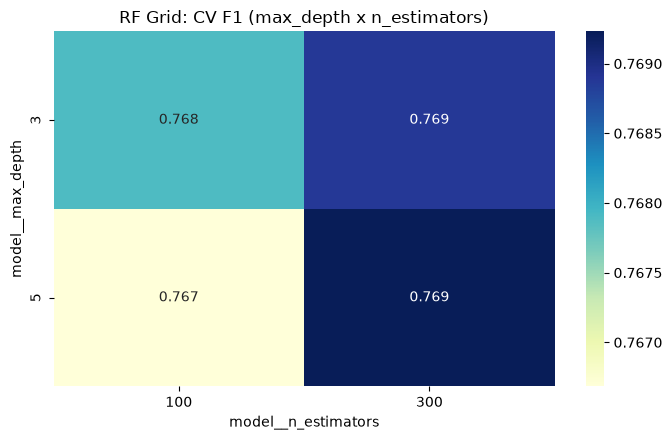

[Random Forest - Random Search] Best CV F1: 0.7792 (+/- 0.0217) | Test F1: 0.7376 | 7.24s


,Hyperparameters,CV F1 Mean,CV F1 Std,Train F1 Mean
0,"{'model__class_weight': 'balanced', 'model__ma...",0.779187,0.021745,0.869519
1,"{'model__class_weight': 'balanced', 'model__ma...",0.778025,0.017056,0.813765
2,"{'model__class_weight': 'balanced', 'model__ma...",0.770570,0.025129,0.831015
3,"{'model__class_weight': None, 'model__max_dept...",0.753664,0.008177,0.791679
4,"{'model__class_weight': None, 'model__max_dept...",0.752429,0.013345,0.794854


[Random Forest - Optuna Bayesian] Best CV F1: 0.7606 (+/- 0.009) | Test F1: 0.766 | 4.99s

--- Random Forest Tuning Comparison ---


,Method,Best CV F1 Mean,CV F1 Std,Train F1,Train-CV Gap,Test Accuracy,Precision,Recall,Test F1,Time (s),Candidates
0,Baseline,0.7562,0.0199,0.9834,0.2272,0.7989,0.7391,0.7391,0.7391,8.53,1
1,Grid,0.7835,0.0223,0.8384,0.0549,0.8045,0.7297,0.7826,0.7552,28.68,32
2,Random,0.7792,0.0217,0.8695,0.0903,0.7933,0.7222,0.7536,0.7376,7.24,5
3,Bayesian,0.7606,0.0090,0.7930,0.0324,0.8156,0.7500,0.7826,0.7660,4.99,5


In [5]:
# 1. Baseline Evaluation
rf_base_pipe = run_baseline("Random Forest", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1))

# 2. Grid Search
rf_param_grid = {
    "model__n_estimators": [100, 300],
    "model__max_depth": [3, 5, 10, None],
    "model__min_samples_leaf": [1, 5],
    "model__max_features": ["sqrt", 0.5],
    "model__class_weight": [None, "balanced"]
}
rf_grid, rf_grid_pipe = run_grid(
    "Random Forest",
    make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)),
    trim_grid(rf_param_grid)
)
show_top(rf_grid.cv_results_)
plot_heatmap(rf_grid.cv_results_, "model__n_estimators", "model__max_depth", "RF Grid: CV F1 (max_depth x n_estimators)")

# 3. Random Search
rf_distributions = {
    "model__n_estimators": randint(100, 601),
    "model__max_depth": [*range(3, 21), None],
    "model__min_samples_split": randint(2, 21),
    "model__min_samples_leaf": randint(1, 11),
    "model__max_features": ["sqrt", "log2", 0.3, 0.5, 0.8],
    "model__class_weight": [None, "balanced"]
}
rf_random, rf_random_pipe = run_random(
    "Random Forest",
    make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)),
    rf_distributions
)
show_top(rf_random.cv_results_)

# 4. Bayesian Optimization (Optuna)
def rf_trial(trial):
    max_depth_raw = trial.suggest_categorical("max_depth", ["none", 3, 5, 7, 10, 15, 20])
    cw_raw = trial.suggest_categorical("class_weight", ["none", "balanced"])
    
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 600),
        "max_depth": None if max_depth_raw == "none" else max_depth_raw,
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", 0.3, 0.5, 0.8]),
        "class_weight": None if cw_raw == "none" else cw_raw
    }
    return make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1, **params))

rf_study, rf_optuna_pipe = run_optuna("Random Forest", rf_trial)

# 5. Method Comparison Table for Random Forest
rf_df = pd.DataFrame([r for r in results if r["Model"] == "Random Forest"])
display_cols = ["Method", "Best CV F1 Mean", "CV F1 Std", "Train F1", "Train-CV Gap",
                "Test Accuracy", "Precision", "Recall", "Test F1", "Time (s)", "Candidates"]
print("\n--- Random Forest Tuning Comparison ---")
display(rf_df[display_cols].reset_index(drop=True))

### XGBoost: Tuning and Evaluation

XGBoost builds trees sequentially where each tree learns from the residual errors of preceding trees, applying second-order gradient approximations and regularization ($L_1$ and $L_2$).

**Key Hyperparameters:**
| Hyperparameter | What it controls | Direction to reduce overfitting | Range searched |
|---|---|---|---|
| `learning_rate` | Shrinkage step size applied to tree weights | Smaller values prevent overfitting (requires more trees) | 0.01 to 0.3 (log scale) |
| `n_estimators` | Number of boosting rounds | Fewer trees (or pair higher values with lower learning rate) | 100 to 600 |
| `max_depth` | Maximum tree depth | Smaller values constrain tree capacity (typically 2 to 6) | 2 to 8 |
| `min_child_weight` | Minimum sum of instance weight (Hessian) in a child | Larger values prevent leaf nodes from isolating noisy samples | 1 to 10 |
| `gamma` | Minimum loss reduction required to make a further partition | Larger values lead to more conservative tree pruning | 0 to 5 |
| `subsample` | Ratio of training rows sampled per tree | Lower values (< 1.0) introduce randomness to combat variance | 0.6 to 1.0 |
| `colsample_bytree` | Ratio of feature columns sampled per tree | Lower values (< 1.0) reduce correlation between trees | 0.6 to 1.0 |
| `reg_alpha` ($L_1$) | Lasso regularization on leaf weights | Larger values encourage sparsity in leaf scores | 1e-3 to 10 (log scale) |
| `reg_lambda` ($L_2$) | Ridge regularization on leaf weights | Larger values penalize extreme leaf scores | 1e-2 to 10 (log scale) |
| `scale_pos_weight` | Balances positive vs negative class weights | Set near negative/positive ratio (~1.6) to boost minority recall | 1.0 to 2.0 |

**Search Strategy:**
- **Baseline:** Default parameters with `eval_metric="logloss"`.
- **Grid Search:** Key interactions tuned first (`learning_rate`, `max_depth`, `subsample`, `reg_lambda`).
- **Random & Bayesian Search:** Wide-range exploration over tree structure, subsampling rates, and $L_1$/$L_2$ penalties.

[XGBoost - Baseline] CV F1: 0.7513 (+/- 0.0181) | Test F1: 0.7591 | Fit Time: 1.66s
[XGBoost - Grid Search] Best CV F1: 0.7789 (+/- 0.017) | Test F1: 0.7463 | 6.63s


,Hyperparameters,CV F1 Mean,CV F1 Std,Train F1 Mean
0,"{'model__colsample_bytree': 1.0, 'model__learn...",0.778874,0.016985,0.925143
1,"{'model__colsample_bytree': 1.0, 'model__learn...",0.770062,0.007056,0.883919
2,"{'model__colsample_bytree': 0.8, 'model__learn...",0.765991,0.020355,0.916861
3,"{'model__colsample_bytree': 1.0, 'model__learn...",0.763364,0.015090,0.907202
4,"{'model__colsample_bytree': 1.0, 'model__learn...",0.763046,0.019794,0.919288


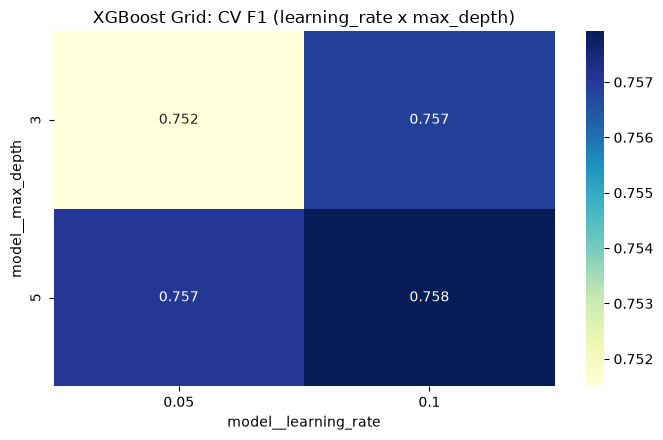

[XGBoost - Random Search] Best CV F1: 0.7691 (+/- 0.0155) | Test F1: 0.7586 | 0.68s


,Hyperparameters,CV F1 Mean,CV F1 Std,Train F1 Mean
0,"{'model__colsample_bytree': 0.9, 'model__gamma...",0.769060,0.015496,0.795314
1,"{'model__colsample_bytree': 0.8, 'model__gamma...",0.764021,0.028552,0.772245
2,"{'model__colsample_bytree': 0.8, 'model__gamma...",0.763632,0.006191,0.781107
3,"{'model__colsample_bytree': 0.8, 'model__gamma...",0.758427,0.018375,0.841142
4,"{'model__colsample_bytree': 0.9, 'model__gamma...",0.678023,0.046669,0.693032


[XGBoost - Optuna Bayesian] Best CV F1: 0.7651 (+/- 0.0121) | Test F1: 0.7826 | 0.8s

--- XGBoost Tuning Comparison ---


,Method,Best CV F1 Mean,CV F1 Std,Train F1,Train-CV Gap,Test Accuracy,Precision,Recall,Test F1,Time (s),Candidates
0,Baseline,0.7513,0.0181,0.9760,0.2247,0.8156,0.7647,0.7536,0.7591,1.66,1
1,Grid,0.7789,0.0170,0.9251,0.1462,0.8101,0.7692,0.7246,0.7463,6.63,64
2,Random,0.7691,0.0155,0.7953,0.0262,0.8045,0.7237,0.7971,0.7586,0.68,5
3,Bayesian,0.7651,0.0121,0.8606,0.0955,0.8324,0.7826,0.7826,0.7826,0.80,5


In [6]:
# 1. Baseline Evaluation for XGBoost
xgb_base_pipe = run_baseline(
    "XGBoost", 
    XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=1)
)

# 2. Grid Search for XGBoost
xgb_param_grid = {
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [3, 5],
    "model__n_estimators": [100, 300],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0],
    "model__reg_lambda": [1, 5]
}
xgb_grid, xgb_grid_pipe = run_grid(
    "XGBoost",
    make_pipeline(XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=1)),
    trim_grid(xgb_param_grid)
)
show_top(xgb_grid.cv_results_)
plot_heatmap(xgb_grid.cv_results_, "model__learning_rate", "model__max_depth", "XGBoost Grid: CV F1 (learning_rate x max_depth)")

# 3. Random Search for XGBoost
xgb_distributions = {
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2, 0.3],
    "model__n_estimators": randint(100, 601),
    "model__max_depth": randint(2, 9),
    "model__min_child_weight": randint(1, 11),
    "model__gamma": [0, 0.5, 1.0, 2.0, 5.0],
    "model__subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0],
    "model__reg_alpha": [0.001, 0.01, 0.1, 1.0, 10.0],
    "model__reg_lambda": [0.01, 0.1, 1.0, 5.0, 10.0],
    "model__scale_pos_weight": [1.0, 1.3, 1.6, 2.0]
}
xgb_random, xgb_random_pipe = run_random(
    "XGBoost",
    make_pipeline(XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=1)),
    xgb_distributions
)
show_top(xgb_random.cv_results_)

# 4. Bayesian Optimization (Optuna) for XGBoost
def xgb_trial(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 100, 600),
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0.0, 5.0),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-2, 10.0, log=True),
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1.0, 2.0)
    }
    return make_pipeline(XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=1, **params))

xgb_study, xgb_optuna_pipe = run_optuna("XGBoost", xgb_trial)

# 5. Method Comparison Table for XGBoost
xgb_df = pd.DataFrame([r for r in results if r["Model"] == "XGBoost"])
display_cols = ["Method", "Best CV F1 Mean", "CV F1 Std", "Train F1", "Train-CV Gap",
                "Test Accuracy", "Precision", "Recall", "Test F1", "Time (s)", "Candidates"]
print("\n--- XGBoost Tuning Comparison ---")
display(xgb_df[display_cols].reset_index(drop=True))

## Support Vector Machine (SVM): Tuning and Evaluation

Support Vector Classifiers construct an optimal hyperplane maximizing the separation margin between classes in high-dimensional space.

**Why Feature Scaling is Mandatory:**
SVM computes geometric distances between feature vectors. Without standardization (`StandardScaler` in our pipeline), features with larger raw ranges (e.g., `Fare` spanning 0 to 500) would dominate distance calculations and suppress binary or small-scale signals (e.g., `Sex` or `Pclass`).

**Key Hyperparameters:**
| Hyperparameter | What it controls | Direction to reduce overfitting | Range searched |
|---|---|---|---|
| `kernel` | Maps input vectors into higher-dimensional space | Linear is less flexible (high bias); RBF captures non-linear boundaries | RBF vs Linear |
| `C` | Regularization penalty for misclassified points | Smaller values widen the margin, tolerating more training violations | 1e-2 to 1e3 (log scale) |
| `gamma` | Influence radius of individual support vectors (RBF only) | Smaller values create smoother, flatter decision boundaries | 1e-4 to 10 (log scale) |
| `class_weight` | Balances margin penalties per class | Use "balanced" to avoid predicting mostly majority non-survivors | None, balanced |

**The $C$-$\gamma$ Interaction:**
A high $C$ combined with a high $\gamma$ forces the model to fit every training point tightly, resulting in extreme overfitting. We search both parameters across logarithmic scales to find a balanced margin.

[SVM - Baseline] CV F1: 0.7643 (+/- 0.0074) | Test F1: 0.791 | Fit Time: 0.11s
[SVM - Grid Search] Best CV F1: 0.7691 (+/- 0.0198) | Test F1: 0.7815 | 0.49s


,Hyperparameters,CV F1 Mean,CV F1 Std,Train F1 Mean
0,"{'model__C': 1, 'model__class_weight': 'balanc...",0.769142,0.019759,0.797350
1,"{'model__C': 1, 'model__class_weight': None, '...",0.764294,0.007396,0.797595
2,"{'model__C': 1, 'model__class_weight': None, '...",0.763124,0.009459,0.767337
3,"{'model__C': 0.1, 'model__class_weight': None,...",0.758819,0.012195,0.767453
4,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.750775,0.004947,0.771629


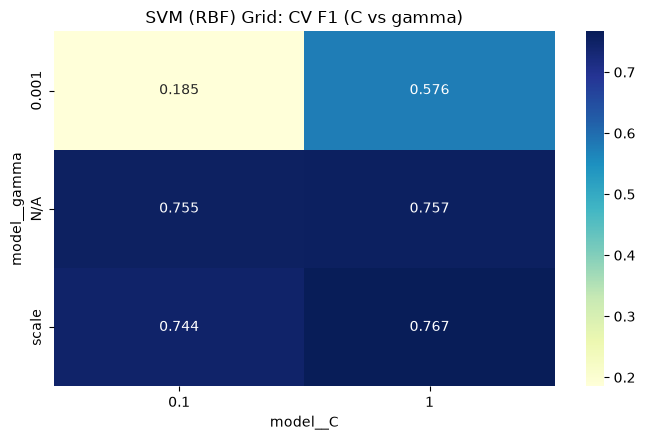

[SVM - Random Search] Best CV F1: 0.7726 (+/- 0.0079) | Test F1: 0.7669 | 7.83s


,Hyperparameters,CV F1 Mean,CV F1 Std,Train F1 Mean
0,"{'model__kernel': 'rbf', 'model__gamma': 0.006...",0.772617,0.007875,0.803797
1,"{'model__kernel': 'rbf', 'model__gamma': 0.042...",0.770380,0.019122,0.805259
2,"{'model__kernel': 'linear', 'model__gamma': 0....",0.760149,0.007402,0.766307
3,"{'model__kernel': 'rbf', 'model__gamma': 0.002...",0.758737,0.009351,0.773218
4,"{'model__kernel': 'rbf', 'model__gamma': 0.000...",0.752095,0.010390,0.764286


[SVM - Optuna Bayesian] Best CV F1: 0.7601 (+/- 0.0074) | Test F1: 0.7597 | 0.49s

--- SVM Tuning Comparison ---


,Method,Best CV F1 Mean,CV F1 Std,Train F1,Train-CV Gap,Test Accuracy,Precision,Recall,Test F1,Time (s),Candidates
0,Baseline,0.7643,0.0074,0.7976,0.0333,0.8436,0.8154,0.7681,0.7910,0.11,1
1,Grid,0.7691,0.0198,0.7973,0.0282,0.8156,0.7195,0.8551,0.7815,0.49,12
2,Random,0.7726,0.0079,0.8038,0.0312,0.8268,0.7969,0.7391,0.7669,7.83,5
3,Bayesian,0.7601,0.0074,0.7663,0.0062,0.8268,0.8167,0.7101,0.7597,0.49,5


In [7]:
# 1. Baseline Evaluation for SVM
svm_base_pipe = run_baseline("SVM", SVC(random_state=RANDOM_STATE))

# 2. Grid Search for SVM (Separate sub-grids for RBF and Linear kernels)
svm_param_grid = [
    {
        "model__kernel": ["rbf"],
        "model__C": [0.1, 1, 10, 100],
        "model__gamma": ["scale", 0.001, 0.01, 0.1],
        "model__class_weight": [None, "balanced"]
    },
    {
        "model__kernel": ["linear"],
        "model__C": [0.1, 1, 10],
        "model__class_weight": [None, "balanced"]
    }
]
svm_grid, svm_grid_pipe = run_grid(
    "SVM",
    make_pipeline(SVC(random_state=RANDOM_STATE)),
    trim_grid(svm_param_grid)
)
show_top(svm_grid.cv_results_)

# Plot heatmap for the RBF subset (C vs gamma)
rbf_results = [
    r for r in svm_grid.cv_results_["params"] 
    if r.get("model__kernel") == "rbf"
]
if len(rbf_results) > 0:
    plot_heatmap(svm_grid.cv_results_, "model__C", "model__gamma", "SVM (RBF) Grid: CV F1 (C vs gamma)")

# 3. Random Search for SVM
svm_distributions = {
    "model__kernel": ["rbf", "linear"],
    "model__C": np.logspace(-2, 3, 20),
    "model__gamma": np.logspace(-4, 1, 20),
    "model__class_weight": [None, "balanced"]
}
svm_random, svm_random_pipe = run_random(
    "SVM",
    make_pipeline(SVC(random_state=RANDOM_STATE)),
    svm_distributions
)
show_top(svm_random.cv_results_)

# 4. Bayesian Optimization (Optuna) for SVM
def svm_trial(trial):
    kernel = trial.suggest_categorical("kernel", ["rbf", "linear"])
    cw_raw = trial.suggest_categorical("class_weight", ["none", "balanced"])
    C = trial.suggest_float("C", 1e-2, 1e3, log=True)
    
    params = {
        "kernel": kernel,
        "C": C,
        "class_weight": None if cw_raw == "none" else cw_raw
    }
    if kernel == "rbf":
        params["gamma"] = trial.suggest_float("gamma", 1e-4, 1e1, log=True)
        
    return make_pipeline(SVC(random_state=RANDOM_STATE, **params))

svm_study, svm_optuna_pipe = run_optuna("SVM", svm_trial)

# 5. Method Comparison Table for SVM
svm_df = pd.DataFrame([r for r in results if r["Model"] == "SVM"])
display_cols = ["Method", "Best CV F1 Mean", "CV F1 Std", "Train F1", "Train-CV Gap",
                "Test Accuracy", "Precision", "Recall", "Test F1", "Time (s)", "Candidates"]
print("\n--- SVM Tuning Comparison ---")
display(svm_df[display_cols].reset_index(drop=True))

--- Master Tuning Results (Sorted by CV F1) ---


,Model,Method,Best CV F1 Mean,CV F1 Std,Test Accuracy,Precision,Recall,Test F1,Time (s),Candidates,Train-CV Gap
0,Random Forest,Grid,0.7835,0.0223,0.8045,0.7297,0.7826,0.7552,28.68,32,0.0549
1,Random Forest,Random,0.7792,0.0217,0.7933,0.7222,0.7536,0.7376,7.24,5,0.0903
2,XGBoost,Grid,0.7789,0.0170,0.8101,0.7692,0.7246,0.7463,6.63,64,0.1462
3,SVM,Random,0.7726,0.0079,0.8268,0.7969,0.7391,0.7669,7.83,5,0.0312
4,SVM,Grid,0.7691,0.0198,0.8156,0.7195,0.8551,0.7815,0.49,12,0.0282
5,XGBoost,Random,0.7691,0.0155,0.8045,0.7237,0.7971,0.7586,0.68,5,0.0262
6,XGBoost,Bayesian,0.7651,0.0121,0.8324,0.7826,0.7826,0.7826,0.80,5,0.0955
7,SVM,Baseline,0.7643,0.0074,0.8436,0.8154,0.7681,0.7910,0.11,1,0.0333
8,Random Forest,Bayesian,0.7606,0.0090,0.8156,0.7500,0.7826,0.7660,4.99,5,0.0324
9,SVM,Bayesian,0.7601,0.0074,0.8268,0.8167,0.7101,0.7597,0.49,5,0.0062


,Model,Method,Best Params
0,Random Forest,Baseline,{}
1,Random Forest,Grid,"{'model__class_weight': 'balanced', 'model__ma..."
2,Random Forest,Random,"{'model__class_weight': 'balanced', 'model__ma..."
3,Random Forest,Bayesian,"{'max_depth': 3, 'class_weight': 'balanced', '..."
4,XGBoost,Baseline,{}
5,XGBoost,Grid,"{'model__colsample_bytree': 1.0, 'model__learn..."
6,XGBoost,Random,"{'model__colsample_bytree': 0.9, 'model__gamma..."
7,XGBoost,Bayesian,"{'learning_rate': 0.010725209743171996, 'n_est..."
8,SVM,Baseline,{}
9,SVM,Grid,"{'model__C': 1, 'model__class_weight': 'balanc..."


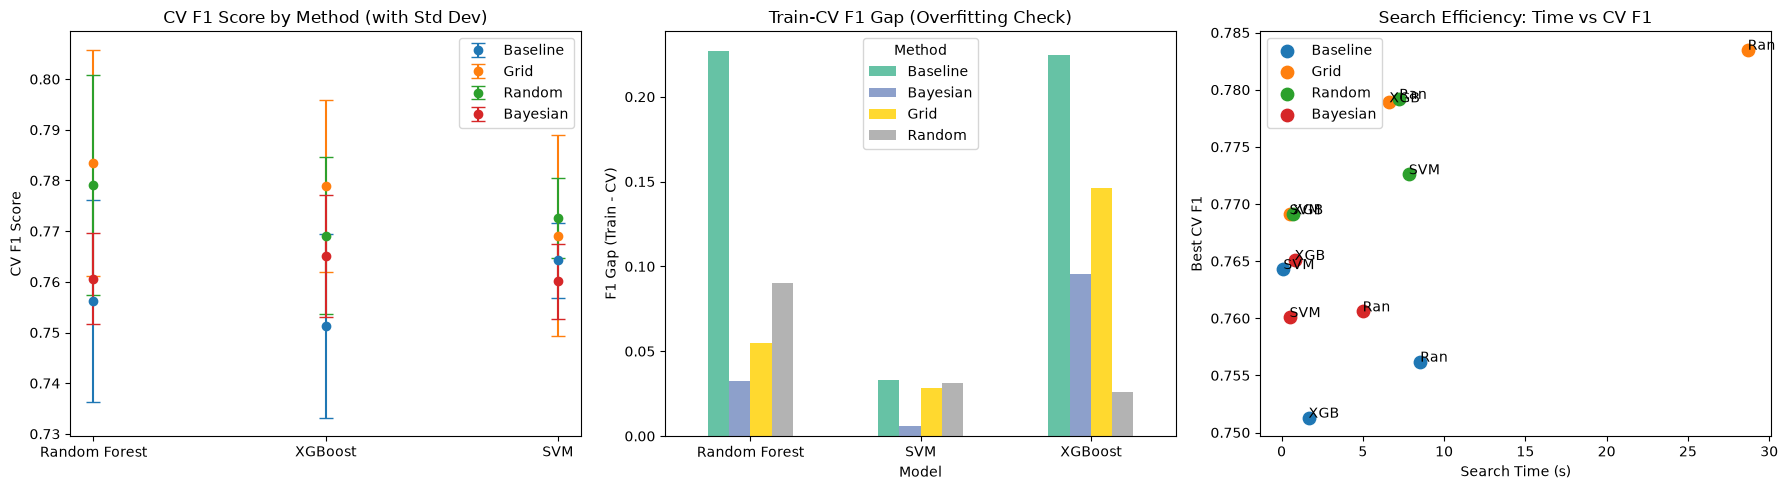


Winner selected by CV F1: Random Forest (Grid)


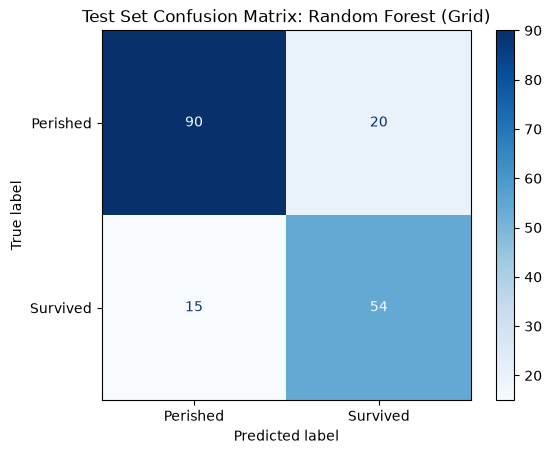

              precision    recall  f1-score   support

    Perished       0.86      0.82      0.84       110
    Survived       0.73      0.78      0.76        69

    accuracy                           0.80       179
   macro avg       0.79      0.80      0.80       179
weighted avg       0.81      0.80      0.81       179



In [8]:
# 1. Master Results Summary Table
master_df = pd.DataFrame(results)
summary_cols = ["Model", "Method", "Best CV F1 Mean", "CV F1 Std", 
                "Test Accuracy", "Precision", "Recall", "Test F1", 
                "Time (s)", "Candidates", "Train-CV Gap"]
master_summary = master_df[summary_cols].sort_values("Best CV F1 Mean", ascending=False).reset_index(drop=True)
master_summary.to_csv("master_tuning_results.csv", index=False)

print("--- Master Tuning Results (Sorted by CV F1) ---")
display(master_summary)

# 2. Table of Best Hyperparameter Configurations Found
best_params_df = master_df[["Model", "Method", "Best Params"]].copy()
display(best_params_df)

# 3. Model Comparison Visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot A: CV F1 with Standard Deviation Error Bars
for method in master_df["Method"].unique():
    sub = master_df[master_df["Method"] == method]
    axes[0].errorbar(sub["Model"], sub["Best CV F1 Mean"], yerr=sub["CV F1 Std"], 
                     fmt="o", capsize=5, label=method)
axes[0].set_title("CV F1 Score by Method (with Std Dev)")
axes[0].set_ylabel("CV F1 Score")
axes[0].legend()

# Plot B: Train vs CV Gap (Overfitting Check)
gap_pivot = master_df.pivot(index="Model", columns="Method", values="Train-CV Gap")
gap_pivot.plot(kind="bar", ax=axes[1], colormap="Set2")
axes[1].set_title("Train-CV F1 Gap (Overfitting Check)")
axes[1].set_ylabel("F1 Gap (Train - CV)")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)

# Plot C: Search Efficiency (Time vs CV F1)
for method in master_df["Method"].unique():
    sub = master_df[master_df["Method"] == method]
    axes[2].scatter(sub["Time (s)"], sub["Best CV F1 Mean"], s=80, label=method)
    for _, row in sub.iterrows():
        axes[2].annotate(f"{row['Model'][:3]}", (row["Time (s)"], row["Best CV F1 Mean"]))
axes[2].set_title("Search Efficiency: Time vs CV F1")
axes[2].set_xlabel("Search Time (s)")
axes[2].set_ylabel("Best CV F1")
axes[2].legend()

plt.tight_layout()
plt.show()

# 4. Final Evaluation: Best Overall Model on Held-out Test Set
# We pick the winner strictly by CV F1 (never by test score) to avoid data snooping
best_model_row = master_summary.iloc[0]
best_model_name = best_model_row["Model"]
best_method_name = best_model_row["Method"]

# Select the corresponding best pipeline
if best_model_name == "Random Forest":
    best_pipe = {"Baseline": rf_base_pipe, "Grid": rf_grid_pipe, "Random": rf_random_pipe, "Bayesian": rf_optuna_pipe}[best_method_name]
elif best_model_name == "XGBoost":
    best_pipe = {"Baseline": xgb_base_pipe, "Grid": xgb_grid_pipe, "Random": xgb_random_pipe, "Bayesian": xgb_optuna_pipe}[best_method_name]
else:
    best_pipe = {"Baseline": svm_base_pipe, "Grid": svm_grid_pipe, "Random": svm_random_pipe, "Bayesian": svm_optuna_pipe}[best_method_name]

print(f"\nWinner selected by CV F1: {best_model_name} ({best_method_name})")
test_preds = best_pipe.predict(X_test)
cm = confusion_matrix(y_test, test_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Perished", "Survived"])
disp.plot(cmap="Blues")
plt.title(f"Test Set Confusion Matrix: {best_model_name} ({best_method_name})")
plt.show()

print(classification_report(y_test, test_preds, target_names=["Perished", "Survived"]))